# Git 실습: 할인율 설정 PR 합치기

**이 노트북에서 할 일**

1. 02~05절처럼 팀 원격 저장소와 작성자·리뷰어 저장소를 만듭니다. 같은 모양으로 두 벌 만듭니다.
2. 앞 절의 명령을 함수로 묶어, 작성자의 할인율 설정을 PR로 올리고 main에 합칩니다(실행 1).
3. 환경 파일 이름 하나만 `.env.local`로 바꿔 다시 실행하고, 두 기록장을 비교합니다(실행 2).

**준비물** — API 키 불필요. 실제 비밀 값은 쓰지 않고, 05절의 더미 문자열만 씁니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

01~05절과 같은 실습 폴더 `labs/part1/ch03-git-github`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.
GitHub 계정과 네트워크는 쓰지 않습니다. 새 Git 명령과 새 문법은 없습니다.

## 오늘 볼 그림

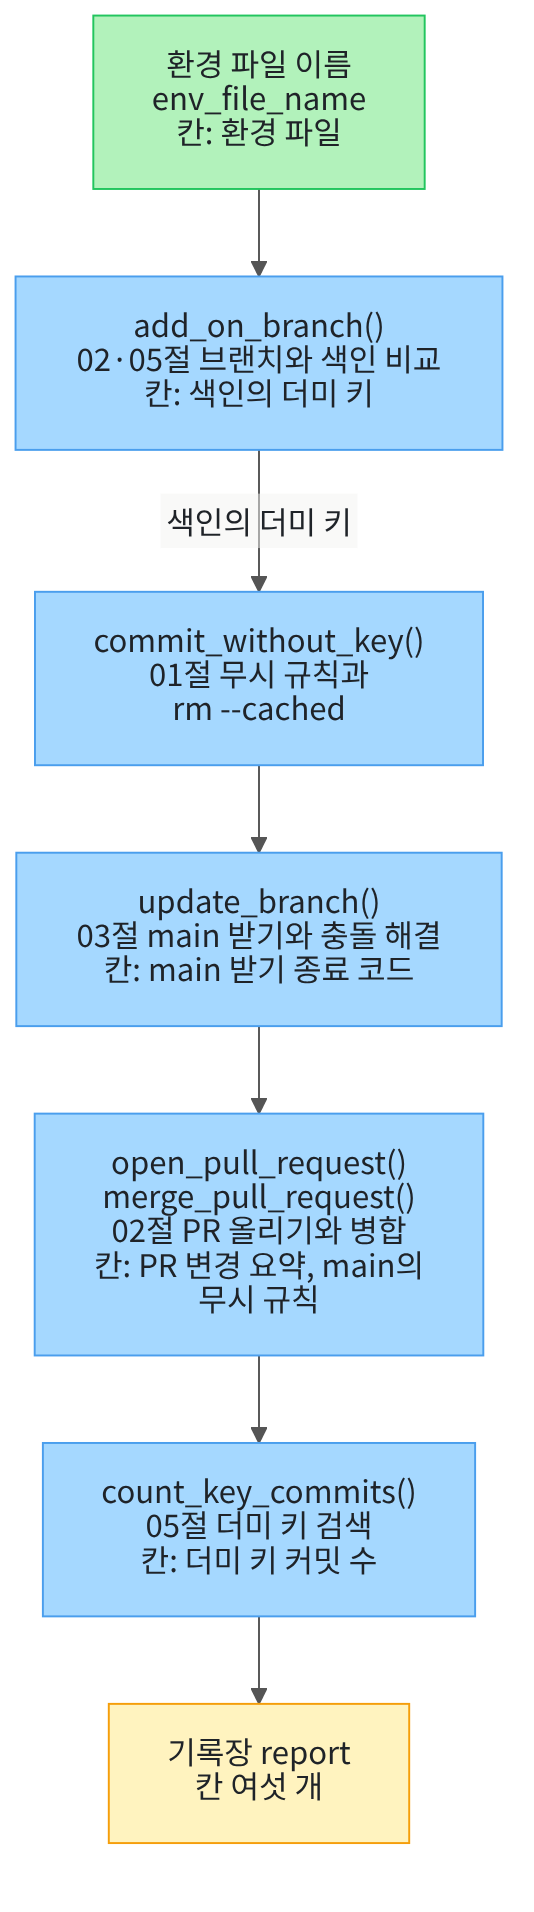

위에서 아래로 읽습니다. 파란 상자는 이 노트북에서 만드는 함수이고, 상자마다 쓰는 절과 기록장에 적는 칸을 적었습니다.
맨 위 초록 상자는 실행 1과 실행 2에서 바꾸는 값인 환경 파일 이름입니다. 맨 아래 노란 상자는 결과를 적는 기록장입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 05절처럼 빈 임시 폴더를 만들고 그 폴더로 작업 위치를 옮깁니다.
폴더 이름의 앞머리만 `ch03-06-`으로 바꿨습니다.

앞에서 배운 함수는 `git_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 2 13절 `print_report()`를 가져옵니다.

가져오는 줄은 작업 위치를 옮기기 전에 둡니다. 도구 파일을 현재 작업 폴더에서 찾기 때문입니다.

In [1]:
# Ch 2 13절 print_report()를 도구 파일에서 가져오고, 저장소들을 담을 빈 임시 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# 작업 위치를 옮기기 전에 가져옵니다. 도구 파일은 노트북과 같은 폴더에 있습니다
from git_tools import print_report

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-06-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.

## 2. git 명령 함수에 반환값 더하기

02~05절의 `run_git()` 함수를 이 노트북에서 다시 정의합니다. 도구 파일에도 있는 함수지만, 이번에는 마지막에 `return result` 한 줄을 더합니다.
이 줄은 명령의 실행 결과를 함수 밖으로 반환합니다. 반환값은 Ch 2 04절에서 배웠습니다.

실행 결과에서는 Ch 1 03절과 Ch 2 08절처럼 `.returncode`로 종료 코드를, `.stdout`으로 출력 글을 읽습니다.
이번 실습은 이 두 값을 기록장에 적습니다. 출력을 보여 주는 나머지 줄은 도구 파일의 02절 판과 같습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# git 명령을 폴더 하나에서 실행해 출력을 보여 주고, 실행 결과를 반환하는 함수
import shlex
import subprocess


def run_git(command: str, folder: str = "."):
    full_command = "git " + command
    # split()은 따옴표로 묶은 메시지를 공백이 있어도 한 낱말로 둡니다
    arguments = shlex.split(full_command)
    # cwd 인자에 적은 폴더에서 명령을 실행하고, 글자는 UTF-8 규칙으로 읽습니다
    result = subprocess.run(arguments, capture_output=True, encoding="utf-8", cwd=folder)
    print(folder, "$", full_command)
    print(result.stdout + result.stderr)
    # 종료 코드가 0이 아닐 때만 숫자를 보여 줍니다
    if result.returncode != 0:
        print("종료 코드:", result.returncode)
    # 이번 실습에서 더한 줄: 종료 코드와 출력 글을 함수 밖에서 읽게 합니다
    return result

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 새로 정의하기만 했습니다.

## 3. 실습 주제 — 할인율 설정 PR 합치기

작성자 `Ch3 Student`가 기능 브랜치 `feature/discount`에서 할인율 설정 파일 `config.txt`를 더합니다. 값은 04·05절과 같은 `discount=10`입니다.
작성자는 로컬에서 시험하려고 환경 파일에도 더미 키를 적어 둡니다. 이 변경을 PR로 올리고, 리뷰어 `Ch3 Reviewer`가 main에 병합합니다.

그사이 리뷰어는 main의 무시 규칙에 가상환경 폴더 `.venv/` 한 줄을 더해 올렸습니다. 작성자는 아직 받아 오지 않았습니다.
이번 실습은 이 흐름에 앞 절의 확인 세 가지를 붙입니다. 커밋 전 색인 비교(05절), 올리기 전 main 받기(03절), PR 병합(02절)입니다.

실행 1과 실행 2는 환경 파일 이름 하나만 다릅니다. 실행 1은 `.env`, 실행 2는 05절 값 바꿔 보기의 `.env.local`입니다.

## 4. 재료 만들기 — 같은 팀 저장소 두 벌

두 실행을 비교하려면 두 실행이 같은 상태에서 시작해야 합니다. 그래서 폴더 `run-1`과 `run-2`에 같은 모양의 저장소를 만듭니다.
반복문 `for`로 같은 명령을 두 폴더에 한 번씩 실행합니다. 경로는 폴더 이름에 `"/author"`를 이어 붙여 만듭니다.

첫 셀은 02~05절 순서대로 원격 `team.git`을 만들고 작성자가 복제합니다. 무시 규칙은 01절과 같은 세 줄이고, 줄바꿈은 `\n`으로 적습니다.
실행 전에 예상합니다. 두 폴더 모두 첫 커밋 표시가 나오고, 종료 코드 줄은 없을 것입니다.

In [3]:
# 두 실행에 쓸 팀 저장소를 같은 모양으로 만들고, 작성자가 무시 규칙 세 줄을 첫 커밋으로 올립니다
for run_folder in ["run-1", "run-2"]:
    author = run_folder + "/author"
    run_git("init --bare -b main " + run_folder + "/team.git")
    run_git("clone team.git author", run_folder)
    run_git('config user.name "Ch3 Student"', author)
    run_git("config user.email student@example.com", author)
    # 01절의 무시 규칙 세 줄입니다
    with open(author + "/.gitignore", "w", encoding="utf-8") as file:
        file.write(".env\n__pycache__/\n*.log\n")
    run_git("add .gitignore", author)
    run_git('commit -m "chore: 환경 파일 추적 제외"', author)
    run_git("push -u origin main", author)

. $ git init --bare -b main run-1/team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-06-rl480dxe/run-1/team.git/

run-1 $ git clone team.git author
Cloning into 'author'...
done.

run-1/author $ git config user.name "Ch3 Student"

run-1/author $ git config user.email student@example.com

run-1/author $ git add .gitignore

run-1/author $ git commit -m "chore: 환경 파일 추적 제외"
[main (root-commit) 9c008f9] chore: 환경 파일 추적 제외
 1 file changed, 3 insertions(+)
 create mode 100644 .gitignore

run-1/author $ git push -u origin main
Branch 'main' set up to track remote branch 'main' from 'origin'.
To [사용자 폴더]/tmp/ch03-06-rl480dxe/run-1/team.git
 * [new branch]      main -> main

. $ git init --bare -b main run-2/team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-06-rl480dxe/run-2/team.git/

run-2 $ git clone team.git author
Cloning into 'author'...
done.

run-2/author $ git config user.name "Ch3 Student"

run-2/author $ git config user.email student@example.com

run-2/author

**결과 읽기** — 폴더마다 `main (root-commit)`과 `1 file changed, 3 insertions(+)`가 한 번씩 나왔습니다. 올리기 출력은 `[new branch]`입니다.
종료 코드 줄은 없습니다. 두 폴더의 출력은 폴더 이름만 다릅니다.

경로 앞 `[사용자 폴더]`는 실행 도구가 사용자 폴더 이름을 가린 표시입니다. 커밋 해시는 실행마다 달라 읽지 않습니다.

이제 두 폴더 모두 리뷰어가 원격을 복제합니다. 리뷰어는 무시 규칙 파일 끝에 `.venv/` 한 줄을 더해 main에 올립니다.
파일 끝에 덧붙이는 모드 `"a"`는 01절에서 썼습니다. 작성자는 이 커밋을 아직 받아 오지 않습니다.

실행 전에 예상합니다. 리뷰어의 커밋 요약 줄은 한 줄 더하기이고, 올리기는 거절 없이 `main -> main`일 것입니다.

In [4]:
# 두 팀 모두 리뷰어가 복제하고, main의 무시 규칙에 가상환경 폴더 한 줄을 더해 올립니다
for run_folder in ["run-1", "run-2"]:
    reviewer = run_folder + "/reviewer"
    run_git("clone team.git reviewer", run_folder)
    run_git('config user.name "Ch3 Reviewer"', reviewer)
    run_git("config user.email reviewer@example.com", reviewer)
    with open(reviewer + "/.gitignore", "a", encoding="utf-8") as file:
        file.write(".venv/\n")
    run_git("add .gitignore", reviewer)
    run_git('commit -m "chore: 가상환경 폴더 추적 제외"', reviewer)
    run_git("push", reviewer)

run-1 $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

run-1/reviewer $ git config user.name "Ch3 Reviewer"

run-1/reviewer $ git config user.email reviewer@example.com

run-1/reviewer $ git add .gitignore

run-1/reviewer $ git commit -m "chore: 가상환경 폴더 추적 제외"
[main 3072a57] chore: 가상환경 폴더 추적 제외
 1 file changed, 1 insertion(+)

run-1/reviewer $ git push
To [사용자 폴더]/tmp/ch03-06-rl480dxe/run-1/team.git
   9c008f9..3072a57  main -> main

run-2 $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

run-2/reviewer $ git config user.name "Ch3 Reviewer"

run-2/reviewer $ git config user.email reviewer@example.com

run-2/reviewer $ git add .gitignore

run-2/reviewer $ git commit -m "chore: 가상환경 폴더 추적 제외"
[main 3072a57] chore: 가상환경 폴더 추적 제외
 1 file changed, 1 insertion(+)

run-2/reviewer $ git push
To [사용자 폴더]/tmp/ch03-06-rl480dxe/run-2/team.git
   9c008f9..3072a57  main -> main



**결과 읽기** — 폴더마다 커밋 요약 줄은 `1 file changed, 1 insertion(+)`이고, 올리기 출력 끝은 `main -> main`입니다.
두 팀의 원격 main은 이제 커밋 두 개입니다. 작성자 폴더의 main은 아직 첫 커밋에 머물러 있습니다.

## 5. 부품 준비 — 작성자가 브랜치에서 커밋하기

첫 부품 `add_on_branch()`는 02절처럼 기능 브랜치를 만들고, 파일 두 개를 씁니다. 할인율 파일과 더미 키를 적은 환경 파일입니다.
그다음 05절 Before처럼 `git add .`으로 폴더의 변경을 한꺼번에 색인에 올립니다.

색인에 올린 뒤에는 05절처럼 `git diff --cached`로 커밋에 들어갈 내용을 읽습니다. 이번에는 사람 대신 코드가 읽습니다.
출력 글 `result.stdout`에 더미 문자열이 들어 있는지 Ch 2 03절의 `in`으로 확인하고, 그 결과(`True`/`False`)를 반환합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [5]:
# 기능 브랜치에서 파일 두 개를 색인에 올리고, 커밋 전 비교 출력에 더미 키가 있는지 반환합니다
def add_on_branch(run_folder: str, env_file_name: str):
    author = run_folder + "/author"
    run_git("switch -c feature/discount", author)
    with open(author + "/config.txt", "w", encoding="utf-8") as file:
        file.write("discount=10\n")
    # 05절의 더미 문자열을 환경 파일에 적습니다
    with open(author + "/" + env_file_name, "w", encoding="utf-8") as file:
        file.write("DEMO_API_KEY=DEMO-ONLY-NOT-A-REAL-SECRET\n")
    run_git("add .", author)
    result = run_git("diff --cached", author)
    key_found = "DEMO-ONLY-NOT-A-REAL-SECRET" in result.stdout
    return key_found

**결과 읽기** — 예상대로 출력이 없습니다. 브랜치를 만들고 파일을 쓰는 일은 함수를 부를 때 실행됩니다.

둘째 부품 `commit_without_key()`는 앞 함수가 반환한 값 `key_found`를 받습니다. 더미 키를 찾았을 때만 여러 줄 `if` 아래를 실행합니다.
그 세 줄은 05절 Before에서 작성자가 한 방법과 같습니다. 무시 규칙 파일 끝에 환경 파일 이름을 더합니다.
이어서 01절의 `git rm --cached`로 그 파일을 색인에서만 빼고, 바뀐 무시 규칙을 색인에 올립니다.

매개변수 `key_found` 옆의 `bool`은 Ch 2 01절에서 배운 불리언 자료형으로, 값이 `True`나 `False`라는 표시입니다.
Ch 2 07절에서 본 것처럼 타입힌트는 값을 검사하지 않습니다.

05절과 다른 점은 순서입니다. 05절은 커밋해 올린 뒤에 고쳤고, 이번에는 커밋하기 전에 고칩니다.
찾지 못했으면 바로 커밋합니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [6]:
# 더미 키를 찾았으면 환경 파일을 무시 규칙에 더하고 색인에서만 뺀 뒤, 할인율 설정을 커밋합니다
def commit_without_key(run_folder: str, env_file_name: str, key_found: bool):
    author = run_folder + "/author"
    if key_found:
        with open(author + "/.gitignore", "a", encoding="utf-8") as file:
            file.write(env_file_name + "\n")
        # 파일은 폴더에 남기고 색인에서만 뺍니다
        run_git("rm --cached " + env_file_name, author)
        run_git("add .gitignore", author)
    run_git('commit -m "feat: 할인율 설정 추가"', author)

**결과 읽기** — 예상대로 출력이 없습니다. 매개변수 `key_found`에는 앞 함수의 반환값을 넣을 것입니다.

셋째 부품 `update_branch()`는 PR을 올리기 전에 원격 main을 받아 기능 브랜치에 합칩니다. 03절의 `git fetch`와 `git merge origin/main`입니다.
병합이 충돌로 멈추면 03절처럼 종료 코드가 1입니다. 그래서 반환받은 실행 결과의 `.returncode`가 0이 아닐 때 충돌을 해결합니다.

03절에서는 충돌 표시를 읽고 기준 파일에 맞춰 새 줄을 정했습니다. 이번에 충돌이 날 수 있는 곳은 무시 규칙 파일뿐입니다.
두 사람이 더한 규칙은 모두 필요하므로, 두 줄을 함께 남긴 글을 미리 적어 둡니다. 해결 뒤에는 03절처럼 색인에 올리고 커밋합니다.

함수는 병합 명령의 종료 코드를 반환합니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [7]:
# 원격 main을 받아 기능 브랜치에 병합하고, 충돌하면 두 사람의 규칙을 모두 남겨 마친 뒤 종료 코드를 반환합니다
def update_branch(run_folder: str, env_file_name: str):
    author = run_folder + "/author"
    run_git("fetch", author)
    result = run_git('merge origin/main -m "merge: main의 무시 규칙 받기"', author)
    if result.returncode != 0:
        # 01절 세 줄 뒤에 리뷰어의 .venv/와 작성자가 더한 환경 파일 이름을 함께 둡니다
        with open(author + "/.gitignore", "w", encoding="utf-8") as file:
            file.write(".env\n__pycache__/\n*.log\n.venv/\n" + env_file_name + "\n")
        run_git("add .gitignore", author)
        run_git('commit -m "merge: main의 무시 규칙 받기"', author)
    return result.returncode

**결과 읽기** — 예상대로 출력이 없습니다. 작성자 쪽 부품 세 개를 모두 정의했습니다.

## 6. 부품 준비 — PR 올리기와 병합

넷째 부품 `open_pull_request()`는 02절처럼 PR로 볼 변경 범위를 `git diff --stat origin/main...HEAD`로 봅니다. 그다음 기능 브랜치를 원격에 올립니다.
변경 범위 출력의 마지막 줄은 `1 file changed`처럼 바뀐 파일 수를 적은 요약입니다.

출력 글은 Ch 2 05절의 `splitlines()`로 줄 목록으로 나눕니다. 마지막 줄은 Ch 1 03절처럼 번호 `[-1]`로 꺼냅니다.
앞의 공백은 Ch 1 04절의 `strip()`으로 떼고 반환합니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [8]:
# PR로 볼 변경 범위를 확인하고 기능 브랜치를 올린 뒤, 변경 요약 줄을 반환합니다
def open_pull_request(run_folder: str):
    author = run_folder + "/author"
    result = run_git("diff --stat origin/main...HEAD", author)
    stat_lines = result.stdout.splitlines()
    run_git("push -u origin feature/discount", author)
    # 마지막 줄이 바뀐 파일 수와 더한 줄 수를 적은 요약입니다
    summary = stat_lines[-1]
    return summary.strip()

**결과 읽기** — 예상대로 출력이 없습니다. 기능 브랜치 이름은 02절처럼 `feature/`로 시작합니다.

다섯째 부품 `merge_pull_request()`는 리뷰어 쪽 일입니다. 02절처럼 받아 온 뒤 `git merge --no-ff`로 기능 브랜치를 main에 병합하고 올립니다.
병합한 뒤에는 main의 무시 규칙 파일을 Ch 2 05절처럼 읽어 줄 목록으로 반환합니다. 기록장에 규칙이 몇 줄 남았는지 적기 위해서입니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [9]:
# 리뷰어가 기능 브랜치를 main에 병합해 올리고, 병합한 main의 무시 규칙을 줄 목록으로 반환합니다
def merge_pull_request(run_folder: str):
    reviewer = run_folder + "/reviewer"
    run_git("fetch", reviewer)
    run_git('merge --no-ff origin/feature/discount -m "merge: 할인율 설정"', reviewer)
    run_git("push", reviewer)
    with open(reviewer + "/.gitignore", "r", encoding="utf-8") as file:
        rules_text = file.read()
    rules = rules_text.splitlines()
    return rules

**결과 읽기** — 예상대로 출력이 없습니다. 기능 브랜치를 올리고 병합하는 부품 두 개를 정의했습니다.

## 7. 기록 장치 — 더미 키 검색과 기록장 출력

두 실행을 비교하려면 결과를 같은 칸에 적어 둬야 합니다. Ch 2 13절처럼 딕셔너리를 기록장으로 씁니다.
기록장에 적을 값 가운데 하나는 05절의 더미 키 검색 결과입니다.

함수 `count_key_commits()`는 리뷰어 저장소에서 `git log --oneline --all -S`로 더미 문자열을 넣거나 뺀 커밋을 찾습니다.
검색 출력의 줄 수가 곧 그런 커밋의 수이므로, 줄 목록의 길이를 반환합니다.
기록장을 칸마다 한 줄씩 출력하는 함수는 Ch 2 13절의 `print_report()`이고, 1번 준비 셀에서 도구 파일로 가져왔습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [10]:
# 리뷰어 저장소의 모든 이름에서 더미 키를 넣거나 뺀 커밋을 찾아 그 수를 반환합니다
def count_key_commits(run_folder: str):
    reviewer = run_folder + "/reviewer"
    result = run_git("log --oneline --all -S DEMO-ONLY-NOT-A-REAL-SECRET", reviewer)
    commit_lines = result.stdout.splitlines()
    return len(commit_lines)

**결과 읽기** — 예상대로 출력이 없습니다. 이 함수는 조립 함수의 마지막 단계에서 부릅니다.

## 8. 조립하기 — 폴더와 환경 파일 이름으로 기록장까지

조립 함수 `run_pull_request()`는 폴더 이름과 환경 파일 이름을 받습니다. 부품 여섯 개를 차례로 부르고, 반환값을 기록장에 적습니다.
줄마다 붙인 주석에 그 줄이 쓰는 절을 적었습니다.

기록장은 칸 하나를 가진 딕셔너리로 시작해, Ch 2 03절처럼 키를 하나씩 추가합니다. 칸은 모두 여섯 개입니다. 환경 파일, 색인의 더미 키, main 받기 종료 코드, PR 변경 요약, main의 무시 규칙, 더미 키 커밋 수입니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 조립: 폴더와 환경 파일 이름을 받아 브랜치 커밋 → main 받기 → PR 병합 → 기록장까지 이어 붙입니다
def run_pull_request(run_folder: str, env_file_name: str):
    report = {"환경 파일": env_file_name}
    # 02절 기능 브랜치, 05절 git add .와 커밋 전 비교 읽기
    report["색인의 더미 키"] = add_on_branch(run_folder, env_file_name)
    # 01절 무시 규칙과 rm --cached, 커밋
    commit_without_key(run_folder, env_file_name, report["색인의 더미 키"])
    # 03절 main 받기와 충돌 해결
    report["main 받기 종료 코드"] = update_branch(run_folder, env_file_name)
    # 02절 PR 변경 범위, 올리기, 리뷰어의 병합
    report["PR 변경 요약"] = open_pull_request(run_folder)
    report["main의 무시 규칙"] = merge_pull_request(run_folder)
    # 05절 이력 전체의 더미 키 검색
    report["더미 키 커밋 수"] = count_key_commits(run_folder)
    return report

**결과 읽기** — 예상대로 출력이 없습니다. 조립이 끝났습니다. 이제 폴더와 환경 파일 이름만 넣어 부르면 됩니다.

## 9. 실행 1 — 환경 파일 이름 .env

변수 `env_file_name`에 `".env"`를 담아 폴더 `run-1`에서 조립 함수를 부릅니다. 반환된 기록장은 `report_1`에 담고 칸별로 출력합니다.

실행 전에 예상합니다. 무시 규칙 첫 줄에 `.env`가 있으므로 색인 비교에는 `config.txt`만 나오고, 더미 키는 `False`일 것입니다.
작성자는 `config.txt`를, 리뷰어는 `.gitignore`를 고쳤으므로 main 받기는 충돌 없이 종료 코드 0일 것입니다.
더미 키 커밋 수는 0일 것입니다.

In [12]:
# 실행 1: 환경 파일 이름을 .env로 두고, 폴더 run-1에서 PR 한 번을 끝까지 진행합니다
run_folder = "run-1"
env_file_name = ".env"
report_1 = run_pull_request(run_folder, env_file_name)
print("기록장:")
print_report(report_1)

run-1/author $ git switch -c feature/discount
Switched to a new branch 'feature/discount'

run-1/author $ git add .

run-1/author $ git diff --cached
diff --git a/config.txt b/config.txt
new file mode 100644
index 0000000..4e7df79
--- /dev/null
+++ b/config.txt
@@ -0,0 +1 @@
+discount=10

run-1/author $ git commit -m "feat: 할인율 설정 추가"
[feature/discount 1ef49b9] feat: 할인율 설정 추가
 1 file changed, 1 insertion(+)
 create mode 100644 config.txt

run-1/author $ git fetch
From [사용자 폴더]/tmp/ch03-06-rl480dxe/run-1/team
   9c008f9..3072a57  main       -> origin/main

run-1/author $ git merge origin/main -m "merge: main의 무시 규칙 받기"
Merge made by the 'ort' strategy.
 .gitignore | 1 +
 1 file changed, 1 insertion(+)

run-1/author $ git diff --stat origin/main...HEAD
 config.txt | 1 +
 1 file changed, 1 insertion(+)

run-1/author $ git push -u origin feature/discount
Branch 'feature/discount' set up to track remote branch 'feature/discount' from 'origin'.
To [사용자 폴더]/tmp/ch03-06-rl480dxe/run-1/team.gi

**결과 읽기** — 기록장은 `색인의 더미 키 | False`, `main 받기 종료 코드 | 0`, `PR 변경 요약 | 1 file changed, 1 insertion(+)`, `더미 키 커밋 수 | 0`입니다.
칸 「main의 무시 규칙」은 `['.env', '__pycache__/', '*.log', '.venv/']`로 네 줄입니다. 예상과 같습니다.

출력 위쪽의 색인 비교에는 `+++ b/config.txt` 한 파일만 있습니다. main 받기는 `Merge made by the 'ort' strategy.`로 끝났습니다.
「종료 코드:」 줄이 한 번도 나오지 않았으므로 충돌을 해결하는 줄은 실행되지 않았습니다. 리뷰어의 병합 뒤 더미 키 검색은 명령 줄 아래가 비어 있습니다.

## 10. 실행 2 — 환경 파일 이름 하나만 바꾸기

바꾸는 값은 `env_file_name` 하나입니다. 값을 `".env.local"`로 바꾸고, 같은 조립 함수를 부릅니다. 폴더 `run-2`는 재료 단계에서 `run-1`과 같은 모양으로 만든 팀입니다.

실행 전에 예상합니다. 05절 값 바꿔 보기처럼 규칙 `.env`는 `.env.local`에 걸리지 않습니다. 그래서 색인 비교에 더미 키가 나와 `True`일 것입니다.

작성자가 무시 규칙 파일 끝에 한 줄을 더하게 됩니다. 리뷰어도 같은 자리에 `.venv/`를 더했으므로 main 받기는 충돌해 종료 코드 1일 것입니다.
두 경우 모두 커밋 전에 막으므로 더미 키 커밋 수는 0일 것입니다.

In [13]:
# 실행 2: 환경 파일 이름 하나만 .env.local로 바꾸고, 같은 모양의 팀 run-2에서 같은 함수를 부릅니다
run_folder = "run-2"
env_file_name = ".env.local"
report_2 = run_pull_request(run_folder, env_file_name)
print("기록장:")
print_report(report_2)

run-2/author $ git switch -c feature/discount
Switched to a new branch 'feature/discount'

run-2/author $ git add .

run-2/author $ git diff --cached
diff --git a/.env.local b/.env.local
new file mode 100644
index 0000000..df0a337
--- /dev/null
+++ b/.env.local
@@ -0,0 +1 @@
+DEMO_API_KEY=DEMO-ONLY-NOT-A-REAL-SECRET
diff --git a/config.txt b/config.txt
new file mode 100644
index 0000000..4e7df79
--- /dev/null
+++ b/config.txt
@@ -0,0 +1 @@
+discount=10

run-2/author $ git rm --cached .env.local
rm '.env.local'

run-2/author $ git add .gitignore

run-2/author $ git commit -m "feat: 할인율 설정 추가"
[feature/discount 4a72519] feat: 할인율 설정 추가
 2 files changed, 2 insertions(+)
 create mode 100644 config.txt

run-2/author $ git fetch
From [사용자 폴더]/tmp/ch03-06-rl480dxe/run-2/team
   9c008f9..3072a57  main       -> origin/main

run-2/author $ git merge origin/main -m "merge: main의 무시 규칙 받기"
Auto-merging .gitignore
CONFLICT (content): Merge conflict in .gitignore
Automatic merge failed; fix conflict

**결과 읽기** — 기록장은 `색인의 더미 키 | True`, `main 받기 종료 코드 | 1`, `PR 변경 요약 | 2 files changed, 2 insertions(+)`, `더미 키 커밋 수 | 0`입니다.
칸 「main의 무시 규칙」은 `['.env', '__pycache__/', '*.log', '.venv/', '.env.local']`로 다섯 줄입니다. 예상과 같습니다.

출력 위쪽의 색인 비교에는 `+DEMO_API_KEY=DEMO-ONLY-NOT-A-REAL-SECRET` 줄이 보입니다. 그래서 `rm '.env.local'`로 색인에서 뺀 뒤 커밋했습니다.
main 받기는 `CONFLICT (content): Merge conflict in .gitignore`와 `종료 코드: 1`로 멈췄습니다. 함수가 두 규칙을 남긴 글로 해결해 커밋했습니다.
PR 변경 범위에는 `config.txt`와 함께 `.gitignore`가 들어갔습니다.

## 11. 두 기록장 비교하기

두 기록장에서 같은 키의 값끼리 비교합니다. Ch 2 13절의 비교 셀과 같은 모양입니다. 기호 `!=`는 「두 값이 다른가」 비교입니다.

셀 끝의 검사 줄 `assert`는 두 실행 모두 더미 키 커밋 수가 0인지 확인합니다. 이 값은 Git 이력에서 세는 값이라 실행마다 같아야 합니다.
실행 전에 예상합니다. 더미 키 커밋 수만 같고, 나머지 다섯 칸은 달라질 것입니다.

In [14]:
# 두 기록장을 칸마다 비교하고, 달라진 칸의 수를 셉니다
changed_count = 0
for key, value_1 in report_1.items():
    value_2 = report_2[key]
    if value_1 != value_2:
        print("달라짐 |", key, "|", value_1, "->", value_2)
        changed_count += 1
    else:
        print("같음 |", key, "|", value_1)
print("달라진 칸 수:", changed_count)
# 두 실행 모두 팀 저장소 이력에 더미 키를 넣은 커밋이 없어야 합니다
assert report_1["더미 키 커밋 수"] == 0
assert report_2["더미 키 커밋 수"] == 0

달라짐 | 환경 파일 | .env -> .env.local
달라짐 | 색인의 더미 키 | False -> True
달라짐 | main 받기 종료 코드 | 0 -> 1
달라짐 | PR 변경 요약 | 1 file changed, 1 insertion(+) -> 2 files changed, 2 insertions(+)
달라짐 | main의 무시 규칙 | ['.env', '__pycache__/', '*.log', '.venv/'] -> ['.env', '__pycache__/', '*.log', '.venv/', '.env.local']
같음 | 더미 키 커밋 수 | 0
달라진 칸 수: 5


**결과 읽기** — 달라진 칸 수는 `5`입니다. `같음 | 더미 키 커밋 수 | 0` 한 칸만 같았고, 검사 줄 `assert`에서도 멈추지 않았습니다.
달라진 칸은 환경 파일, `색인의 더미 키 | False -> True`, `main 받기 종료 코드 | 0 -> 1`, PR 변경 요약, main의 무시 규칙입니다.

바꾼 값은 환경 파일 이름 하나이고, 함수와 저장소 모양은 그대로입니다. 이름 하나가 무시 규칙에 걸리지 않자 뒤 단계가 차례로 달라졌습니다.
색인 비교에서 멈추고, 규칙 파일을 고치고, 그 줄이 리뷰어의 줄과 충돌했습니다. 그래도 두 실행 모두 더미 키 커밋은 팀 저장소에 없습니다.

## 12. 작성자 폴더에 남은 환경 파일

실행 2에서 `git rm --cached`로 뺀 `.env.local`은 어디에 있을까요? 01절에서 배운 대로 이 명령은 색인에서만 빼고 파일은 남깁니다.
작성자 폴더에서 01절의 `git status --short --ignored`를 실행하고, 폴더 파일 목록에 이름이 있는지도 봅니다.

실행 전에 예상합니다. 무시한 파일 표시가 한 줄 나오고, 파일은 폴더에 있을 것입니다.

In [15]:
# 실행 2의 작성자 폴더에서 .env.local이 무시한 파일로 남았는지 확인합니다
run_git("status --short --ignored", "run-2/author")
file_names = os.listdir("run-2/author")
print(".env.local이 폴더에 있는가:", ".env.local" in file_names)

run-2/author $ git status --short --ignored
!! .env.local

.env.local이 폴더에 있는가: True


**결과 읽기** — 상태 표시는 `!! .env.local` 한 줄이고, 폴더에 있는지는 `True`입니다.
작성자는 로컬에서 환경 파일을 계속 쓸 수 있고, Git은 이 파일을 무시합니다.

## 정리

- 01·02·03·05절의 명령을 부품 여섯 개로 묶어, 브랜치 커밋부터 PR 병합까지 조립 함수 하나로 이었습니다.
- 실행 1(`.env`)은 더미 키를 찾지 않았고, main 받기는 종료 코드 0, PR 변경은 파일 한 개였습니다.
- 실행 2에서 이름만 `.env.local`로 바꾸자 더미 키를 찾아 규칙을 더했고, 그 줄이 충돌해 종료 코드 1이었습니다. 두 실행 모두 더미 키 커밋은 0개였습니다.

이번에는 Linux의 Git 2.34.1로, 임시 폴더의 원격 저장소에서 실행했습니다. 규칙 이름이 다른 파일 한 가지만 실행했습니다.
충돌 표시를 사람이 읽고 고르는 경우와 GitHub PR 화면은 이번에 실행하지 않았습니다.
이 절로 Ch 3이 끝납니다. 다음 챕터 Ch 4에서는 Pandas로 표 데이터를 다루는 것부터 시작합니다.